# Modeling

## 1. Feature engineering

CatBoost predicts `ln(posted_rate)`. Features include cyclical calendar values, cached HERE truck routes, daily market decomposition and residuals, US holidays, and historical city aggregates.

Market curves fit the known `market_index` inputs from train + validation, without rate targets. Each regime has fixed coefficients for `a + b*t + c*t² + u*sin(theta) + v*cos(theta)`. Imputation, residual distributions and city statistics fit separately within each training fold. Training city aggregates exclude the current day.

HERE uses city reference coordinates and the Washington override. Cached runs need no API key. The final cell saves the model and preprocessing. Inference reconstructs missing fixed-route December inputs before applying the saved model; those predictions are conditional on the reconstructed values.


In [1]:
from pathlib import Path
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from catboost import Pool
from sklearn.metrics import mean_absolute_error, mean_squared_error, mean_absolute_percentage_error
import optuna

notebook_dir = Path.cwd() if Path('utils.py').exists() else Path.cwd() / 'notebooks'
sys.path.insert(0, str(notebook_dir.resolve()))

from templates import TimeSeriesCV, HParamsOpt
from utils import (
    DATA_DIR,
    METADATA_COLUMNS,
    load_data,
    fit_imputation_values,
    prepare_data,
    add_time_features,
    here_route_table,
    add_city_route_features,
    MarketIndexFeatures,
    predict_market_curves,
    select_market_curves,
    add_holiday_features,
    PastCityAggregates,
    here_route_geometry,
    example_route_maps,
    shap_summary,
    plot_market_decomposition,
    plot_time_series_folds,
    test_residuals,
    plot_test_residuals,
    worst_prediction_shap,
    save_model_bundle,
    compare_test_outliers,
    plot_outlier_comparison,
    calibrate_rate_interval,
    compare_quote_product,
    plot_quote_product_metrics,
    plot_quote_product_predictions,
)

pd.set_option('display.max_columns', 100)
raw, prediction_template = load_data()
HOLDOUT_DAYS = 14
holdout_start = raw['train'].date.max().normalize() - pd.Timedelta(days=HOLDOUT_DAYS - 1)
development_raw = raw['train'].loc[raw['train'].date < holdout_start].copy()
holdout_raw = raw['train'].loc[raw['train'].date >= holdout_start].copy()
assert not development_raw.empty and not holdout_raw.empty
assert development_raw.date.max() < holdout_raw.date.min()
assert not set(development_raw.load_id) & set(holdout_raw.load_id)
assert len(development_raw) + len(holdout_raw) == len(raw['train'])
print(f'Development: {development_raw.date.min():%Y-%m-%d} to {development_raw.date.max():%Y-%m-%d}, '
      f'{len(development_raw):,} rows; test: {holdout_raw.date.min():%Y-%m-%d} to '
      f'{holdout_raw.date.max():%Y-%m-%d}, {len(holdout_raw):,} rows.')
HERE_SNAPSHOT = '2026-10-12-city-routing-v2'
city_centers = pd.read_csv(DATA_DIR / 'city-coordinates.csv').rename(
    columns={'latitude': 'lat', 'longitude': 'lon'})[['city', 'lat', 'lon']]
for point in pd.read_csv(DATA_DIR / 'routing-coordinate-overrides.csv').itertuples(index=False):
    city_centers.loc[city_centers.city.eq(point.city), ['lat', 'lon']] = [point.lat, point.lon]
assert city_centers.city.is_unique
route_table = here_route_table(city_centers, DATA_DIR / 'route_cache', HERE_SNAPSHOT)


Development: 2025-01-01 to 2025-10-17, 45,817 rows; test: 2025-10-18 to 2025-10-31, 2,183 rows.


,pickup,delivery,distance_miles,driving_hours
0,Dallas,Houston,240.38,3.43
1,Detroit,Atlanta,726.33,11.10
2,Los Angeles,New York,2792.16,41.45


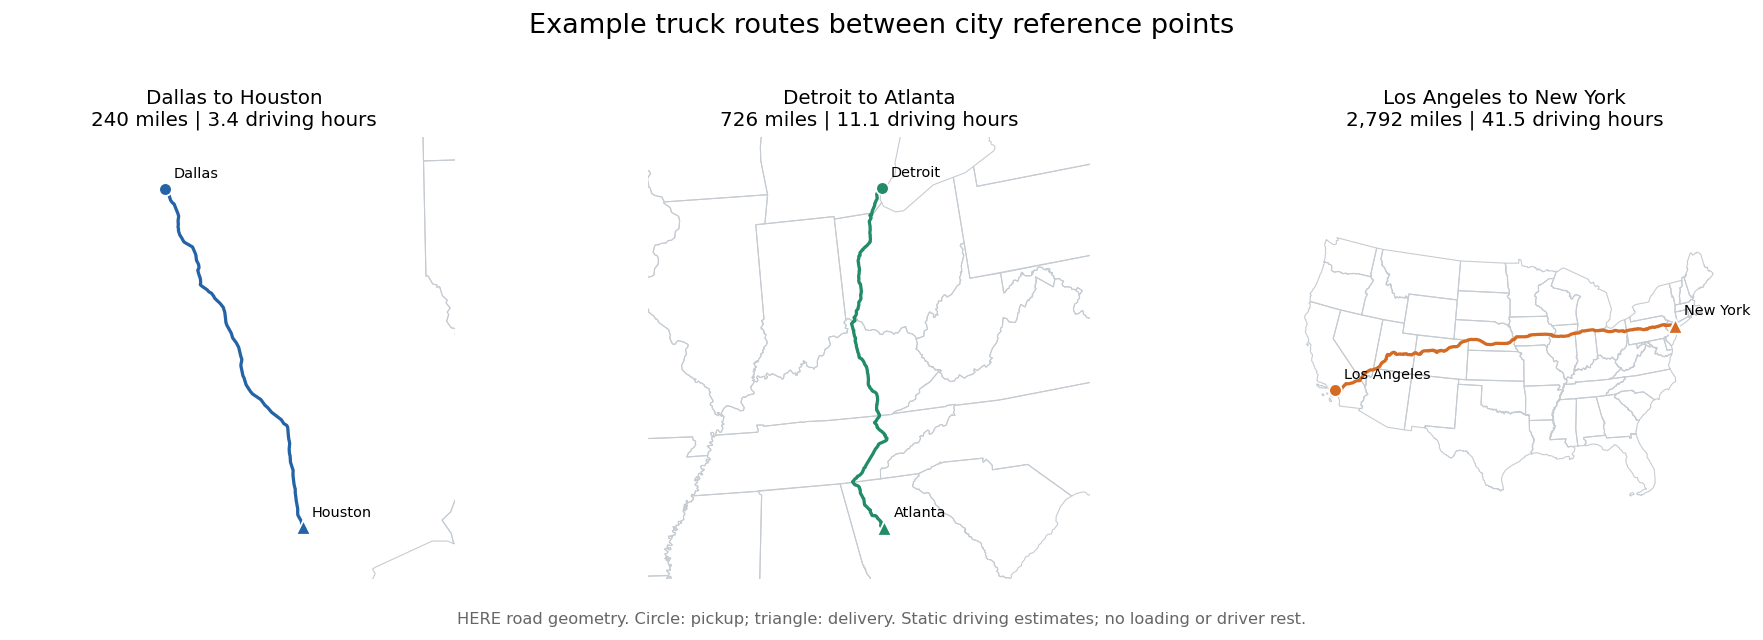

In [2]:
example_pairs = [('Dallas', 'Houston'), ('Detroit', 'Atlanta'), ('Los Angeles', 'New York')]
center_lookup = city_centers.set_index('city')
example_routes = []
for pickup, delivery in example_pairs:
    geometry = here_route_geometry(
        tuple(center_lookup.loc[pickup, ['lat', 'lon']]),
        tuple(center_lookup.loc[delivery, ['lat', 'lon']]),
        DATA_DIR / 'route_cache', HERE_SNAPSHOT,
    )
    example_routes.append({'pickup': pickup, 'delivery': delivery, **geometry})

display(pd.DataFrame([
    {key: route[key] for key in ['pickup', 'delivery', 'distance_miles', 'driving_hours']}
    for route in example_routes
]).round(2))
route_fig = example_route_maps(example_routes, DATA_DIR / 'us-state-outlines-2025.geojson')
route_output = DATA_DIR.parent / 'outputs' / 'example-truck-routes.png'
route_output.parent.mkdir(exist_ok=True)
route_fig.savefig(route_output, dpi=150, facecolor='white')
plt.show()
plt.close(route_fig)


In [3]:
# Market index is an observed inference input, not the target.
# Use all known daily market observations; residual statistics still fit per training fold.
known_market = pd.concat([
    raw[name][['date', 'market_index']] for name in ['train', 'validation']
], ignore_index=True)
known_market_curves = select_market_curves(known_market)

def base_features(frame, fill_values, market_encoder):
    result = add_time_features(prepare_data(frame, fill_values))
    result = add_city_route_features(result, city_centers, route_table)
    observed_market = frame.get('market_index', pd.Series(np.nan, index=frame.index))
    result = market_encoder.transform(result, observed_market)
    return add_holiday_features(result)


def fit_features(frame):
    state = {'fill_values': fit_imputation_values(frame),
             'market_encoder': MarketIndexFeatures.fit(frame, curve_model=known_market_curves),
             'city_encoder': PastCityAggregates(strength=50)}
    result = base_features(frame, state['fill_values'], state['market_encoder'])
    result = result.join(state['city_encoder'].fit_transform(result))
    return result, state


def transform_features(frame, state):
    result = base_features(frame, state['fill_values'], state['market_encoder'])
    return result.join(state['city_encoder'].transform(result))


train_df, feature_state = fit_features(development_raw)
holdout_df = transform_features(holdout_raw, feature_state)
val_df = transform_features(raw['validation'], feature_state)
december_df = transform_features(raw['december'], feature_state)
feature_columns = [column for column in train_df if column not in METADATA_COLUMNS]
cat_features = ['pickup', 'delivery', 'equipment']
market_encoder = feature_state['market_encoder']
market_curves = market_encoder.curve_model
print(f'{len(feature_columns)} predictors prepared.')

assert not holdout_df[feature_columns].isna().any().any()


52 predictors prepared.


,start,end,time_origin,market_coef_intercept,market_coef_linear,market_coef_quadratic,market_coef_weekly_sin,market_coef_weekly_cos,weekly_amplitude
0,2025-01-01,2025-04-15,2025-01-01,0.880028,0.967508,0.051803,0.054973,-0.084535,0.100838
1,2025-04-16,2025-07-24,2025-01-01,0.811936,2.481095,-3.157444,0.054489,-0.083369,0.099596
2,2025-07-25,2025-10-02,2025-01-01,1.795193,-1.565628,0.412586,0.054849,-0.084271,0.100548
3,2025-10-03,2025-12-31,2025-01-01,3.471738,-5.712745,3.198056,0.054391,-0.083524,0.099673


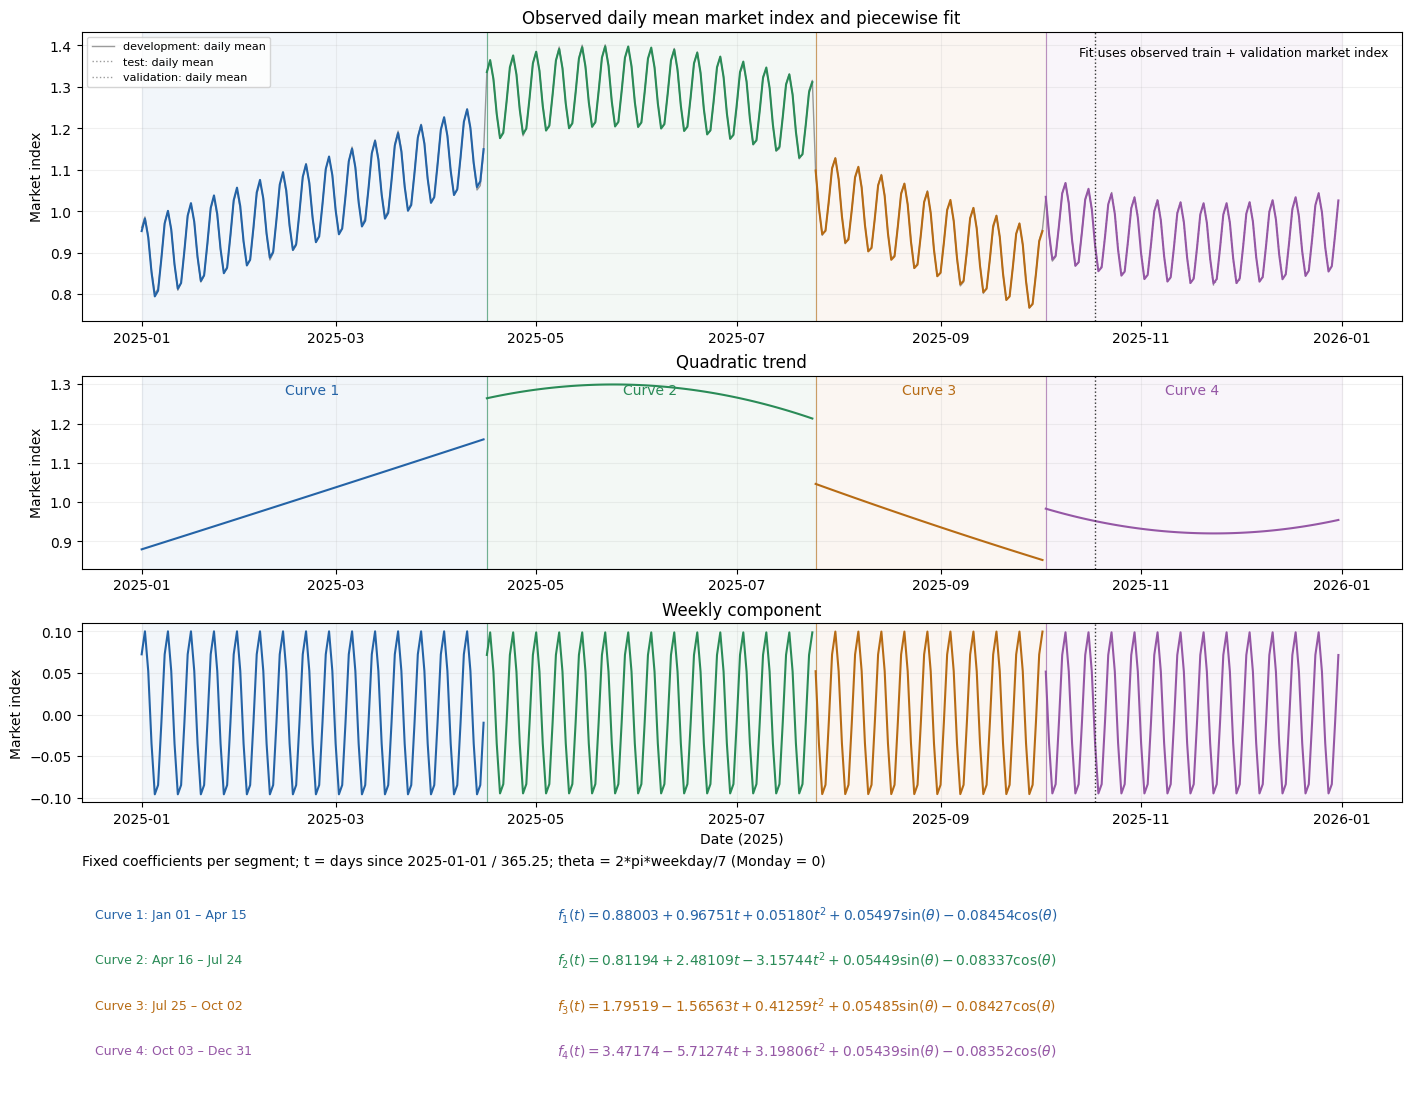

In [4]:
display(market_encoder.coefficient_summary().round(8))
plot_market_decomposition(
    market_encoder, development_raw, holdout_raw, raw['validation'], holdout_start,
    DATA_DIR.parent / 'outputs' / 'market-index-decomposition.png',
)


## 2. Time-series folds and held-out test

Reserve the final 14 calendar days (October 18–31, 2025) as a chronological test. Three expanding CV windows use only the earlier development data; all loads from a day stay together. Refit preprocessing inside every fold. Test targets do not select parameters, iterations, or preprocessing. No combined predictions across folds are constructed.

These dates participated in previous experiments, so this is a retrospectively reserved test, not a completely untouched external evaluation. Keep the boundary fixed and do not tune against its score. The supplied validation remains separate.


In [5]:
cv_source = development_raw.sort_values(['date', 'load_id'])
cv = TimeSeriesCV(n_splits=3)
cv_folds = cv.prepare(
    cv_source, target='posted_rate', feature_columns=feature_columns,
    fit_features=fit_features, transform_features=transform_features,
    metadata_columns=['load_id', 'date'],
)
fold_summary = cv.summary_
assert fold_summary.valid_end.max() < holdout_start
for fold in cv_folds:
    assert not fold['X_train'].isna().any().any() and not fold['X_valid'].isna().any().any()
    assert not set(fold['valid_metadata'].load_id) & set(holdout_raw.load_id)
assert pd.concat([fold['valid_metadata'].load_id for fold in cv_folds]).is_unique
print(f'{len(cv_folds)} temporal folds prepared.')

display(fold_summary)
fold_market_coefficients = pd.concat([
    fold['feature_state']['market_encoder'].coefficient_summary().assign(fold=fold['fold'])
    for fold in cv_folds], ignore_index=True)
display(fold_market_coefficients.round(8))


3 temporal folds prepared.


,fold,train_start,train_end,valid_start,valid_end,train_rows,valid_rows
0,1,2025-01-01,2025-03-15,2025-03-16,2025-05-26,11673,11518
1,2,2025-01-01,2025-05-26,2025-05-27,2025-08-06,23191,11499
2,3,2025-01-01,2025-08-06,2025-08-07,2025-10-17,34690,11127


,start,end,time_origin,market_coef_intercept,market_coef_linear,market_coef_quadratic,market_coef_weekly_sin,market_coef_weekly_cos,weekly_amplitude,fold
0,2025-01-01,2025-04-15,2025-01-01,0.880028,0.967508,0.051803,0.054973,-0.084535,0.100838,1
1,2025-04-16,2025-07-24,2025-01-01,0.811936,2.481095,-3.157444,0.054489,-0.083369,0.099596,1
2,2025-07-25,2025-10-02,2025-01-01,1.795193,-1.565628,0.412586,0.054849,-0.084271,0.100548,1
3,2025-10-03,2025-12-31,2025-01-01,3.471738,-5.712745,3.198056,0.054391,-0.083524,0.099673,1
4,2025-01-01,2025-04-15,2025-01-01,0.880028,0.967508,0.051803,0.054973,-0.084535,0.100838,2
5,2025-04-16,2025-07-24,2025-01-01,0.811936,2.481095,-3.157444,0.054489,-0.083369,0.099596,2
6,2025-07-25,2025-10-02,2025-01-01,1.795193,-1.565628,0.412586,0.054849,-0.084271,0.100548,2
7,2025-10-03,2025-12-31,2025-01-01,3.471738,-5.712745,3.198056,0.054391,-0.083524,0.099673,2
8,2025-01-01,2025-04-15,2025-01-01,0.880028,0.967508,0.051803,0.054973,-0.084535,0.100838,3
9,2025-04-16,2025-07-24,2025-01-01,0.811936,2.481095,-3.157444,0.054489,-0.083369,0.099596,3


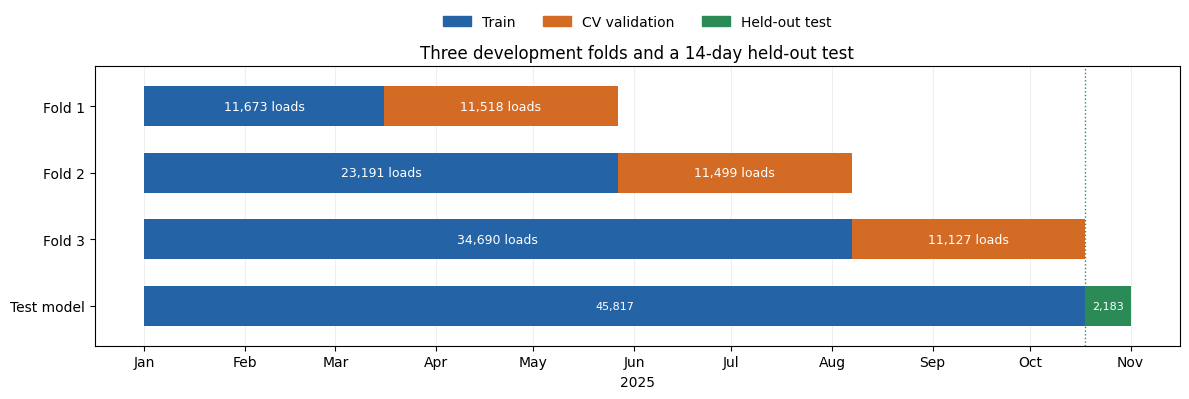

In [6]:
plot_time_series_folds(
    fold_summary, development_raw, holdout_raw, holdout_start,
    DATA_DIR.parent / 'outputs' / 'time-series-cv.png',
)


## 3. Training

`HParamsOpt.catboost` handles conditional parameter search, cached fold pools, log-target transforms, early stopping and model refits. Defaults: 50 TPE trials, 1,500 maximum trees, 100-round early stopping, and seed 42. The objective is `0.2 * MAPE_fold1 + 0.3 * MAPE_fold2 + 0.5 * MAPE_fold3` in original rate units. Search covers growth policy, leaf estimation, column sampling and numeric borders; settings can be overridden with `fixed_params` and `search_space`.

`golden_features` names numeric columns for additional quantization tuning. Each receives its own border count, selected sequentially by weighted CV with all other current settings fixed. Use `[]` to skip. Fold, test and final models receive the selected overrides.

SQLite stores completed trials using a data/configuration fingerprint. The held-out test does not select settings. Refit development and full-train models using the median CV tree count. Predictions stay in memory; pooled OOF is not computed.


In [7]:
N_TRIALS = 50
FOLD_WEIGHTS = [0.2, 0.3, 0.5]
golden_features = ['distance']
border_counts = [254, 512, 1024, 2048]

study_path = DATA_DIR.parent / 'outputs' / 'catboost-optuna.sqlite'
study_path.parent.mkdir(exist_ok=True)
optuna.logging.set_verbosity(optuna.logging.WARNING)
optimizer = HParamsOpt.catboost(
    cv_folds, cat_features=cat_features, weights=FOLD_WEIGHTS, log_target=True,
    study_prefix='holdout14-weighted-mape', storage=f'sqlite:///{study_path.resolve()}',
)
study = optimizer.run(N_TRIALS)
display(pd.Series(study.best_params, name='Best parameter').to_frame())
display(optimizer.tune_golden_features(golden_features, border_counts=border_counts).round(4))
optimizer.golden_metrics_.to_csv(DATA_DIR.parent / 'outputs' / 'golden-features-cv.csv', index=False)
print(f'Golden feature borders: {optimizer.golden_borders_}')

cv_models, cv_metrics = optimizer.fit_folds()
selected_cv_mape = optimizer.selected_cv_score_
final_iterations = int(cv_metrics.iterations.median())

# Freeze choices before scoring the held-out test.
holdout_model = optimizer.fit(train_df[feature_columns], train_df.posted_rate, iterations=final_iterations)
holdout_predictions = holdout_raw[['load_id', 'date']].copy()
holdout_predictions['predicted_rate'] = optimizer.predict(holdout_model, holdout_df[feature_columns])

# Refit on all labeled rows for supplied validation predictions.
full_train_df, final_feature_state = fit_features(raw['train'])
val_df = transform_features(raw['validation'], final_feature_state)
december_df = transform_features(raw['december'], final_feature_state)
final_model = optimizer.fit(full_train_df[feature_columns], full_train_df.posted_rate,
                            iterations=final_iterations)
validation_predictions = val_df[['load_id']].copy()
validation_predictions['predicted_rate'] = optimizer.predict(final_model, val_df[feature_columns])
assert validation_predictions.load_id.is_unique
print(f'Final refit: {final_iterations} trees; {len(validation_predictions):,} validation predictions.')


,Best parameter
depth,6
learning_rate,0.05697
l2_leaf_reg,2.289086
random_strength,1.168622
colsample_bylevel,0.97706
border_count,254
grow_policy,SymmetricTree
leaf_estimation_method,Newton
leaf_estimation_iterations,1
leaf_estimation_backtracking,AnyImprovement


,feature,border_count,weighted_MAPE_pct
0,distance,254,5.1119
1,distance,512,5.2819
2,distance,1024,5.2522
3,distance,2048,5.3171


Golden feature borders: {'distance': 254}


Final refit: 285 trees; 12,000 validation predictions.


## 4. Metrics and SHAP

MAE, RMSE and MAPE use original rate units on each fold's validation rows. The separate 14-day test also reports median/P90 absolute percentage error and the share within 10%. CV scores are development estimates because the same validation windows select hyperparameters and early stopping.

Native CatBoost SHAP values explain `ln(rate)`. Each fold plot uses only its held-out rows; the final plot uses the supplied validation set and the full-train model. Feature ranking uses all rows; each plot displays 1,500 deterministically sampled rows and the top 20 features. Numeric colors run from low (blue) to high (red), clipped at the 5th/95th percentiles; categorical points are gray. Positive SHAP raises the predicted log rate. SHAP is computed without validation targets. Each explanation must pass the additivity check; if native CatBoost SHAP fails it, the plot is skipped with a diagnostic.

CatBoost feature importance uses `PredictionValuesChange`: normalized model importance (sum = 100 across all features), independent of the SHAP values. Show each fold model and the final full-train model.

Compare CatBoost with the unadjusted `quote_signal * distance` baseline on exactly the same fold-validation and test rows. The product has no fitted correction coefficient. Daily test means and actual-vs-predicted plots compare both methods with observed rates.


In [8]:
display(cv_metrics.round(3))

weighted_mape = float(FOLD_WEIGHTS @ cv_metrics.sort_values('fold').MAPE_pct.to_numpy())
assert np.isclose(weighted_mape, selected_cv_mape, rtol=1e-5, atol=1e-5)
print(f'Weighted CV MAPE (0.2 / 0.3 / 0.5): {weighted_mape:.4f}%')
trial_summary = pd.DataFrame([
    {'trial': trial.number, 'weighted_MAPE_pct': trial.value, **trial.params}
    for trial in study.trials if trial.state == optuna.trial.TrialState.COMPLETE
]).sort_values('weighted_MAPE_pct')
display(trial_summary.head(10).round(4))

# Test labels are read for evaluation only, after model choices are frozen.
test_actual = holdout_raw.posted_rate.to_numpy()
test_predicted = holdout_predictions.predicted_rate.to_numpy()
test_ape = 100 * np.abs(test_predicted - test_actual) / test_actual
test_metrics = pd.DataFrame([{
    'rows': len(test_actual), 'MAE': mean_absolute_error(test_actual, test_predicted),
    'RMSE': np.sqrt(mean_squared_error(test_actual, test_predicted)),
    'MAPE_pct': test_ape.mean(), 'Median_APE_pct': np.median(test_ape),
    'P90_APE_pct': np.percentile(test_ape, 90), 'Within_10pct_pct': 100 * (test_ape <= 10).mean(),
}], index=['Held-out test'])
display(test_metrics.round(3))


,fold,iterations,MAE,RMSE,MAPE_pct
0,1,218,133.387,566.842,6.200
1,2,285,127.400,658.064,5.006
2,3,427,108.474,614.069,4.740


Weighted CV MAPE (0.2 / 0.3 / 0.5): 5.1119%


,trial,weighted_MAPE_pct,depth,learning_rate,l2_leaf_reg,random_strength,colsample_bylevel,border_count,grow_policy,leaf_estimation_method,leaf_estimation_iterations,leaf_estimation_backtracking,min_data_in_leaf,max_leaves
41,41,5.1119,6,0.0570,2.2891,1.1686,0.9771,254,SymmetricTree,Newton,1,AnyImprovement,NaN,NaN
0,0,5.1833,6,0.0500,3.0000,1.0000,1.0000,254,SymmetricTree,Newton,1,No,NaN,NaN
1,1,5.1833,6,0.0500,3.0000,1.0000,1.0000,254,SymmetricTree,Gradient,1,No,NaN,NaN
37,37,5.1845,5,0.0603,2.3046,0.6723,0.9199,254,SymmetricTree,Newton,1,AnyImprovement,NaN,NaN
44,44,5.2197,5,0.0510,3.2783,0.5690,0.8760,254,SymmetricTree,Newton,2,AnyImprovement,NaN,NaN
34,34,5.2314,6,0.0459,2.1024,0.0096,0.9891,254,SymmetricTree,Newton,1,No,NaN,NaN
32,32,5.2520,6,0.0556,2.2879,0.0034,0.7673,254,SymmetricTree,Newton,1,No,NaN,NaN
24,24,5.2801,6,0.0386,13.5029,0.0031,0.8333,254,SymmetricTree,Newton,1,No,NaN,NaN
43,43,5.2807,6,0.0708,3.2885,1.1473,0.9609,254,SymmetricTree,Newton,1,AnyImprovement,NaN,NaN
22,22,5.2903,6,0.0202,4.4020,0.0025,0.7529,254,SymmetricTree,Newton,2,No,NaN,NaN


,rows,MAE,RMSE,MAPE_pct,Median_APE_pct,P90_APE_pct,Within_10pct_pct
Held-out test,2183,115.648,706.517,5.556,1.897,4.624,97.939


,split,model,MAE,RMSE,MAPE_pct
0,Fold 1,CatBoost,133.387,566.842,6.200
1,Fold 1,Quote × distance,323.250,696.303,16.298
2,Fold 2,CatBoost,127.400,658.064,5.006
3,Fold 2,Quote × distance,268.881,740.244,12.881
4,Fold 3,CatBoost,108.474,614.069,4.740
5,Fold 3,Quote × distance,239.234,685.905,11.310
6,Test,CatBoost,115.648,706.517,5.556
7,Test,Quote × distance,411.320,838.653,21.028


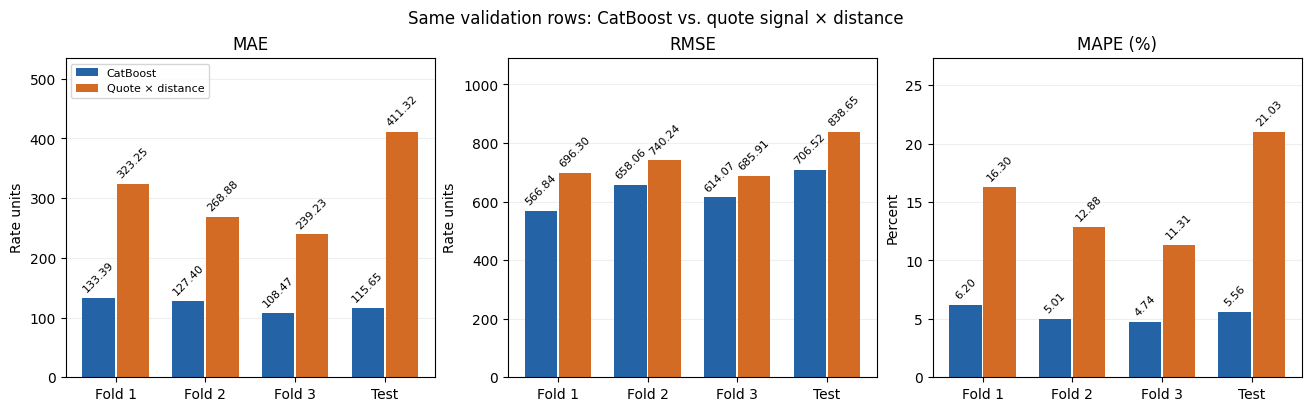

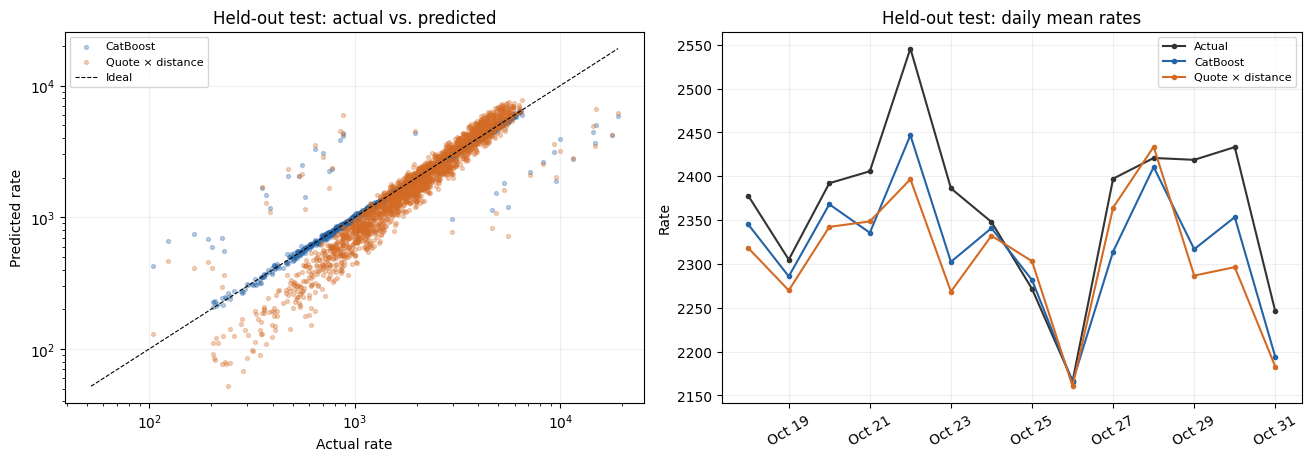

In [9]:
baseline_metrics, baseline_test_comparison = compare_quote_product(
    cv_folds, cv_metrics, holdout_raw, holdout_predictions,
)
display(baseline_metrics.round(3))
metric_figure = plot_quote_product_metrics(baseline_metrics)
metric_figure.savefig(DATA_DIR.parent / 'outputs' / 'catboost-cv-metrics.png', dpi=150, facecolor='white')
plt.show()
plt.close(metric_figure)
baseline_figure = plot_quote_product_predictions(baseline_test_comparison)
baseline_figure.savefig(DATA_DIR.parent / 'outputs' / 'test-quote-product-baseline.png', dpi=150, facecolor='white')
plt.show()
plt.close(baseline_figure)


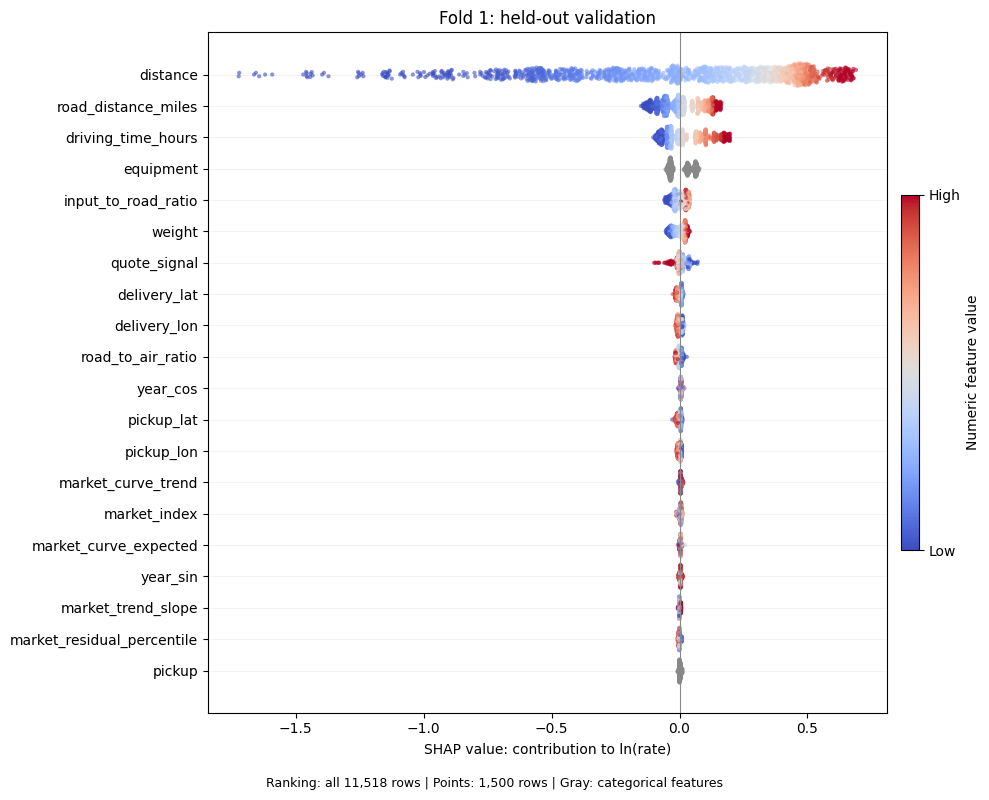

fold_1: SHAP computed for all 11,518 rows; additivity verified.


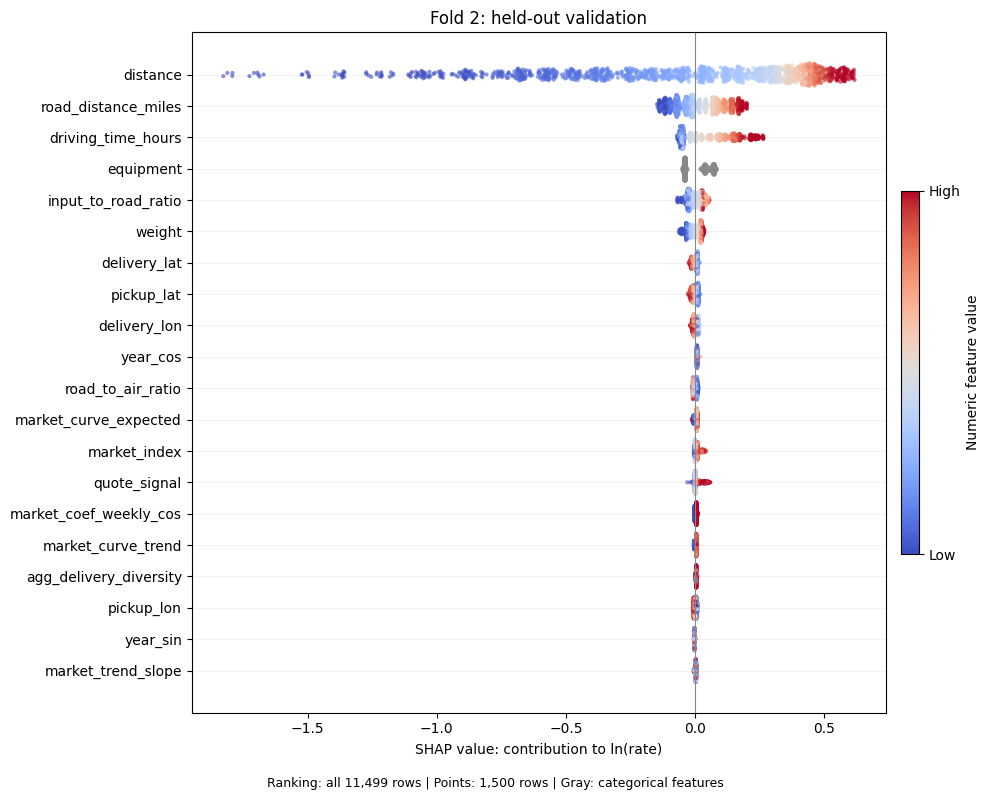

fold_2: SHAP computed for all 11,499 rows; additivity verified.


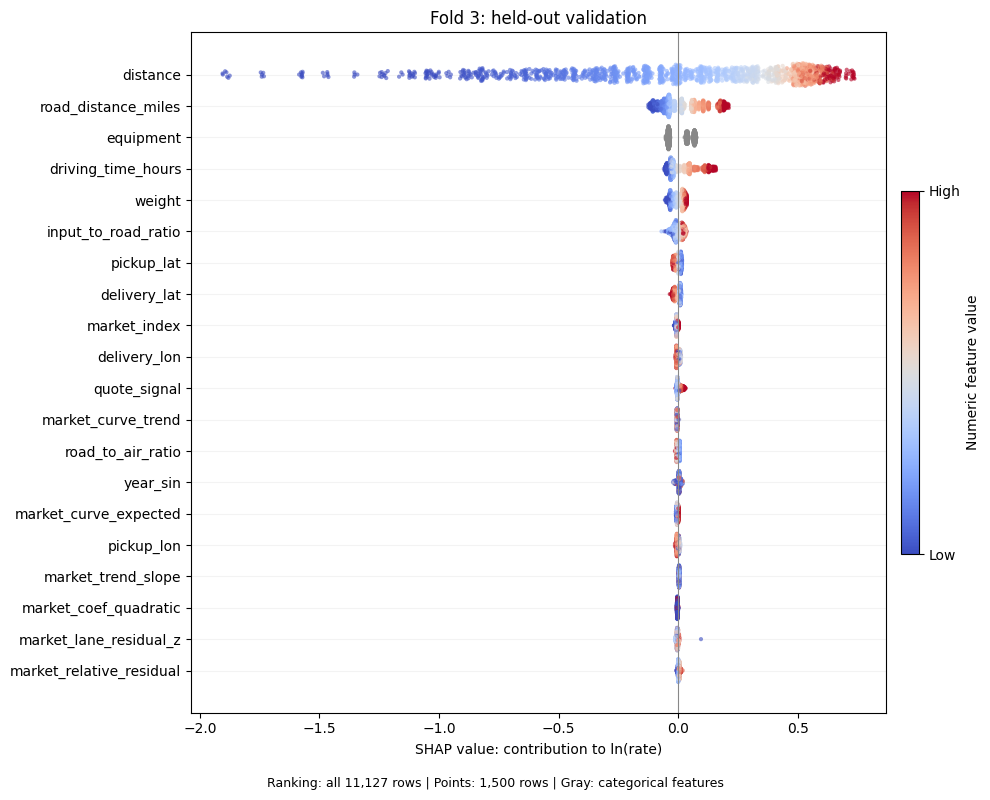

fold_3: SHAP computed for all 11,127 rows; additivity verified.


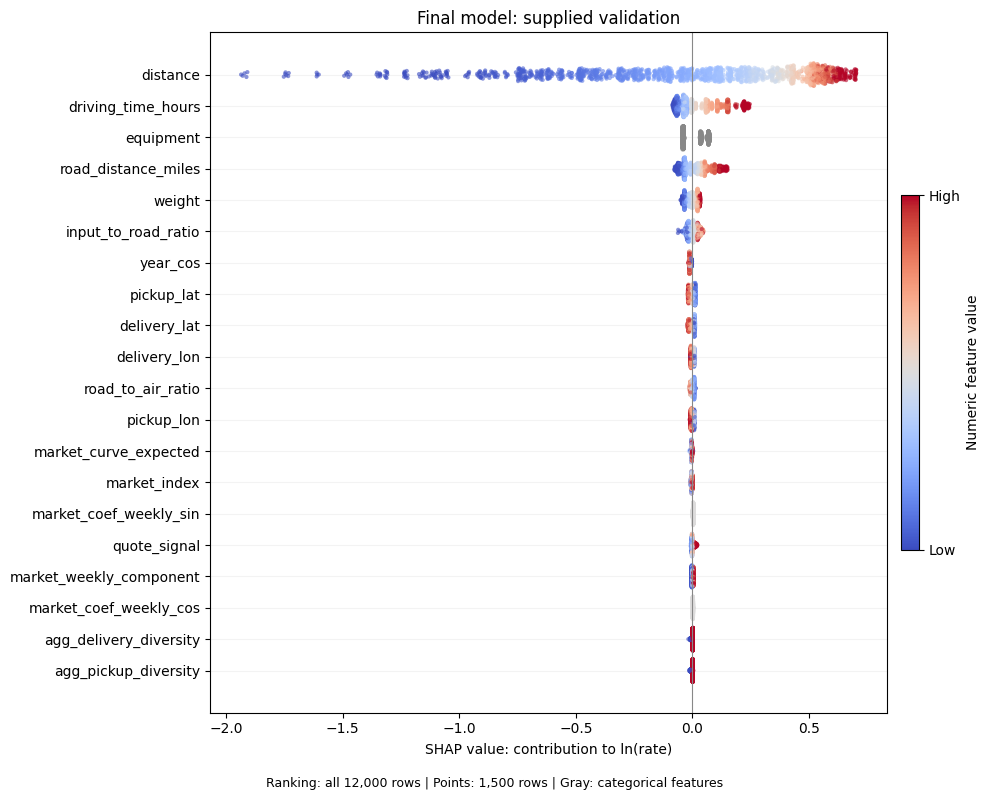

validation: SHAP computed for all 12,000 rows; additivity verified.


In [10]:
shap_results = {}
shap_datasets = [
    (f'fold_{fold["fold"]}', f'Fold {fold["fold"]}: held-out validation', model, fold['X_valid'])
    for fold, model in zip(cv_folds, cv_models)
] + [('validation', 'Final model: supplied validation', final_model, val_df[feature_columns])]
for name, title, model, X in shap_datasets:
    pool = Pool(X, cat_features=cat_features)
    explanation = model.get_feature_importance(pool, type='ShapValues', thread_count=4)
    values, base_values = explanation[:, :-1], explanation[:, -1]
    raw_prediction = model.predict(X, prediction_type='RawFormulaVal')
    if not np.allclose(values.sum(axis=1) + base_values, raw_prediction, rtol=1e-6, atol=1e-6):
        max_error = np.max(np.abs(values.sum(axis=1) + base_values - raw_prediction))
        print(f'{name}: native SHAP failed additivity (max error {max_error:.6g}); plot skipped.')
        (DATA_DIR.parent / 'outputs' / f'shap-{name}.png').unlink(missing_ok=True)
        continue
    shap_results[name] = {'values': values, 'base_values': base_values, 'index': X.index.copy(),
                          'load_ids': raw['train' if name.startswith('fold_') else 'validation'].loc[X.index, 'load_id'].copy(),
                          'feature_names': X.columns.tolist()}
    figure = shap_summary(values, X, title)
    figure.savefig(DATA_DIR.parent / 'outputs' / f'shap-{name}.png', dpi=150, facecolor='white')
    plt.show()
    plt.close(figure)
    print(f'{name}: SHAP computed for all {len(X):,} rows; additivity verified.', flush=True)


## 5. Held-out test residuals

Residual = actual - predicted; positive means underprediction. Rank the five worst loads by absolute percentage error, consistent with MAPE. SHAP decision paths explain the development-only test model in log-rate units; they accumulate feature contributions from the base value to each prediction.

,load_id,date,pickup,delivery,equipment,distance,quote_signal,posted_rate,predicted_rate,residual,APE_pct
46399,TR-046400,2025-10-21,Indianapolis,Madison,Dry Van,276.6,1.692,123.32,657.788,-534.468,433.399
46178,TR-046179,2025-10-20,Philadelphia,Houston,Dry Van,1589.7,2.215,643.58,3292.461,-2648.881,411.585
46173,TR-046174,2025-10-20,Philadelphia,El Paso,Dry Van,2490.9,2.406,880.13,4404.335,-3524.205,400.419
46259,TR-046260,2025-10-20,Hartford,Savannah,Dry Van,829.2,2.063,352.82,1677.180,-1324.360,375.364
47503,TR-047504,2025-10-29,Bakersfield,Montgomery,Reefer,2063.5,2.070,880.04,4167.314,-3287.274,373.537


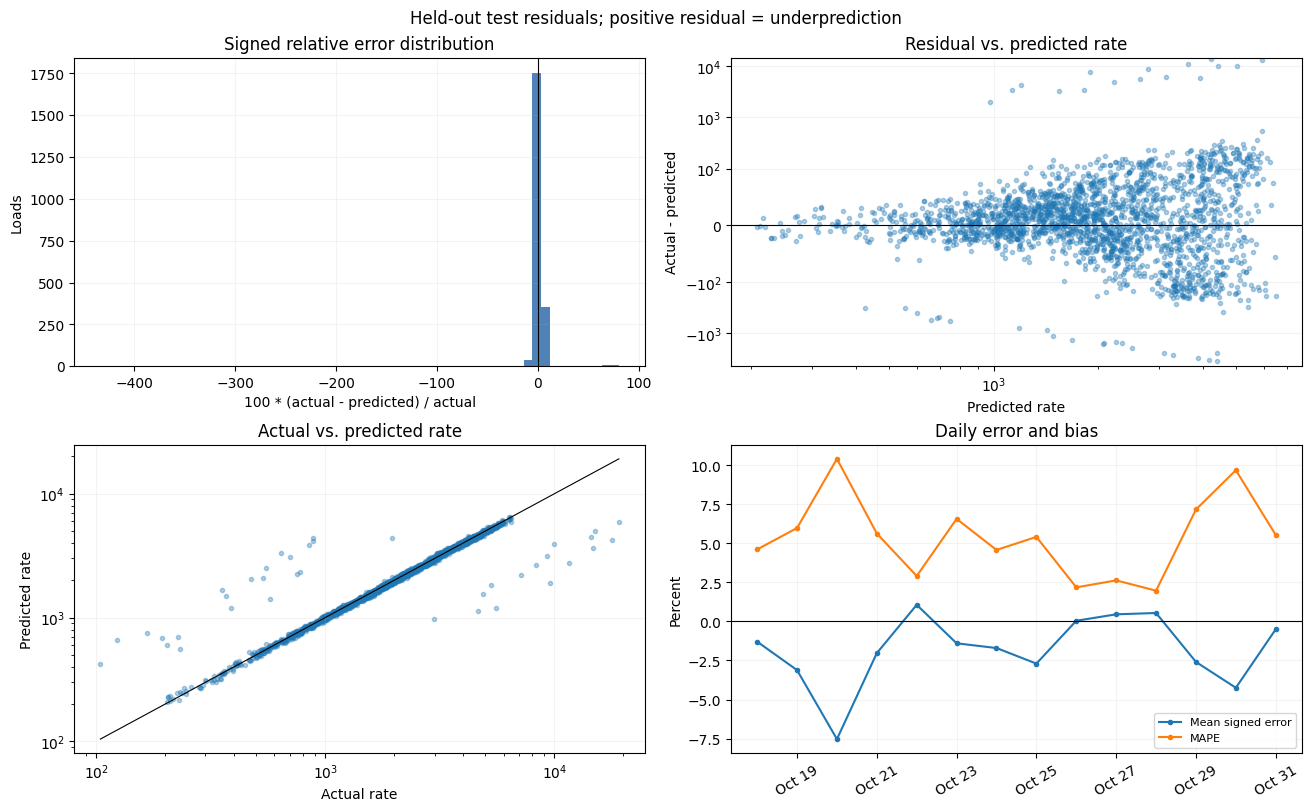

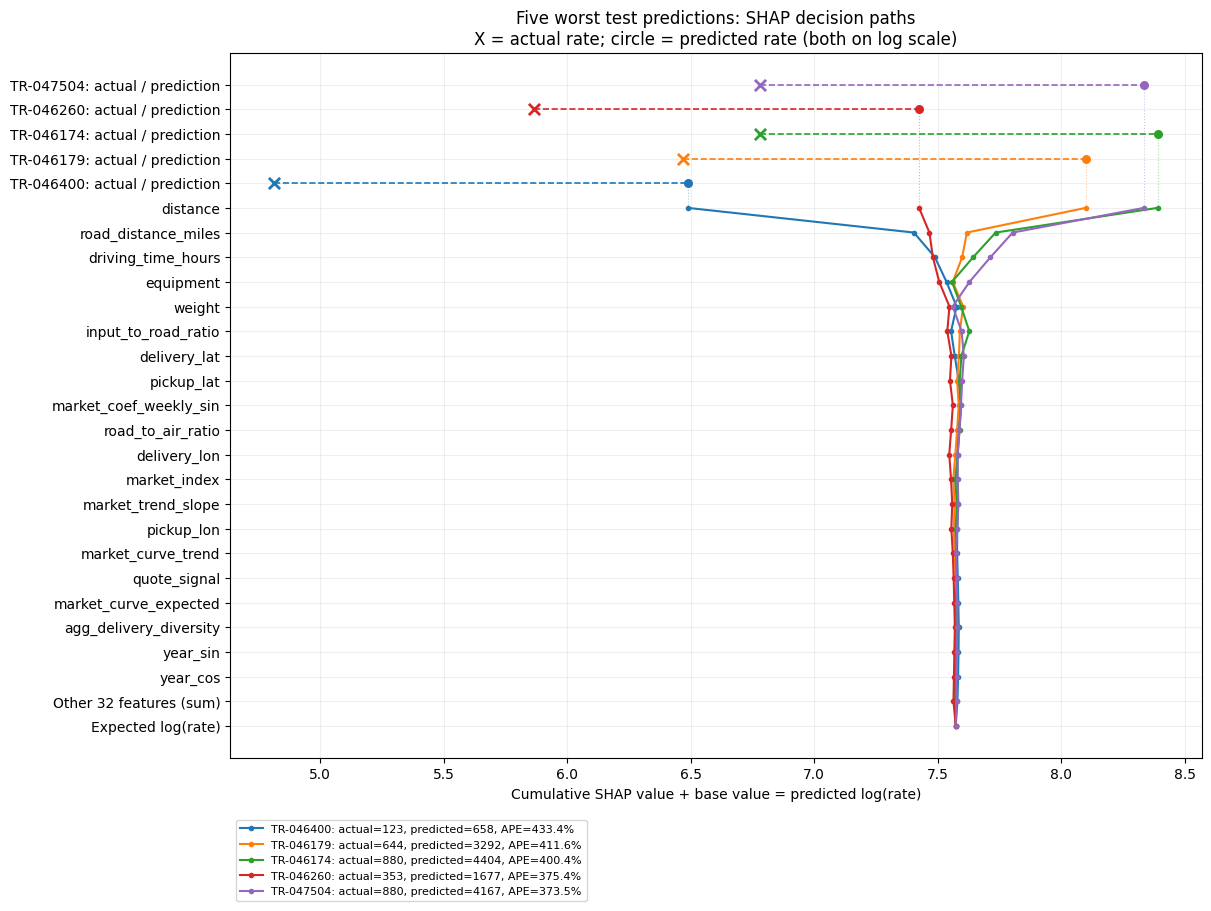

In [11]:
residuals = test_residuals(holdout_raw, holdout_predictions)
worst_test = residuals.sort_values(['APE_pct', 'absolute_error'], ascending=False).head(5)
display(worst_test[['load_id', 'date', 'pickup', 'delivery', 'equipment', 'distance',
                    'quote_signal', 'posted_rate', 'predicted_rate', 'residual', 'APE_pct']].round(3))
residual_figure = plot_test_residuals(residuals)
residual_figure.savefig(DATA_DIR.parent / 'outputs' / 'test-residuals.png', dpi=150, facecolor='white')
plt.show()
plt.close(residual_figure)
worst_figure, worst_shap_values = worst_prediction_shap(
    holdout_model, holdout_df[feature_columns], worst_test, cat_features,
)
worst_figure.savefig(DATA_DIR.parent / 'outputs' / 'test-worst-five-shap.png', dpi=150, facecolor='white')
plt.show()
plt.close(worst_figure)


### High-error loads vs. the rest of the test

Severe errors have APE > 50%; ordinary errors have APE <= 10%. Compare input distributions, route familiarity and equipment/cities. Target/quote ratios are diagnostic only and never enter the model. The five worst loads are also compared with 20 historical loads of the same equipment, matched on distance, weight, quote signal and market index. These are approximate peers, not identical routes.

,rows,MAPE_pct,median_actual,median_prediction,median_target_to_quote,median_actual_to_prediction,row_share_pct,share_of_total_APE_pct,unseen_lane_pct
error_group,,,,,,,,,
APE <= 10%,2138,2.163,2020.925,1992.616,1.094,1.006,97.939,38.131,0.094
Severe: underprediction,16,70.756,9413.575,2706.685,3.621,3.225,0.733,9.334,0.000
Severe: overprediction,22,286.162,505.240,1871.247,0.306,0.248,1.008,51.904,0.000
10% < APE <= 50%,7,10.945,241.410,268.458,2.253,0.901,0.321,0.632,0.000


error_group,10% < APE <= 50%,APE <= 10%,Severe: overprediction,Severe: underprediction
distance,71.600,929.650,884.450,1322.300
road_distance_miles,212.158,924.555,864.795,1215.975
weight,28807.000,31441.000,30934.500,32547.000
market_index,0.869,0.941,0.997,1.011
quote_signal,1.271,1.985,1.938,2.021
road_to_air_ratio,1.178,1.164,1.172,1.150
input_to_road_ratio,0.519,1.016,0.983,1.033
market_curve_residual,0.013,0.001,0.008,0.010
train_lane_count,17.000,14.000,14.500,14.000
posted_rate,241.410,2020.925,505.240,9413.575


,category,severe_rows,other_rows,severe_share_pct,other_share_pct,difference_pp,feature
0,Reefer,12,522,31.58,24.34,7.24,equipment
1,Flatbed,8,420,21.05,19.58,1.47,equipment
2,Dry Van,18,1203,47.37,56.08,-8.72,equipment
3,Memphis,3,32,7.89,1.49,6.4,pickup
4,Bakersfield,3,49,7.89,2.28,5.61,pickup
5,Atlanta,3,56,7.89,2.61,5.28,pickup
6,Hartford,3,58,7.89,2.7,5.19,pickup
7,Corpus Christi,2,30,5.26,1.4,3.86,pickup
8,Atlanta,3,41,7.89,1.91,5.98,delivery
9,Madison,2,24,5.26,1.12,4.14,delivery


,load_id,pickup,delivery,equipment,distance,quote_signal,actual,predicted,APE_pct,historical_peers,peer_rate_median,peer_rate_p10,peer_rate_p90,actual_to_peer_median
0,TR-046400,Indianapolis,Madison,Dry Van,276.6,1.692,123.32,657.788,433.399,20,852.355,756.554,1058.652,0.145
1,TR-046179,Philadelphia,Houston,Dry Van,1589.7,2.215,643.58,3292.461,411.585,20,2970.970,2798.981,3288.473,0.217
2,TR-046174,Philadelphia,El Paso,Dry Van,2490.9,2.406,880.13,4404.335,400.419,20,4282.880,3793.342,4851.590,0.205
3,TR-046260,Hartford,Savannah,Dry Van,829.2,2.063,352.82,1677.180,375.364,20,1617.790,1425.558,1761.953,0.218
4,TR-047504,Bakersfield,Montgomery,Reefer,2063.5,2.070,880.04,4167.314,373.537,20,4185.065,3833.959,4423.726,0.210


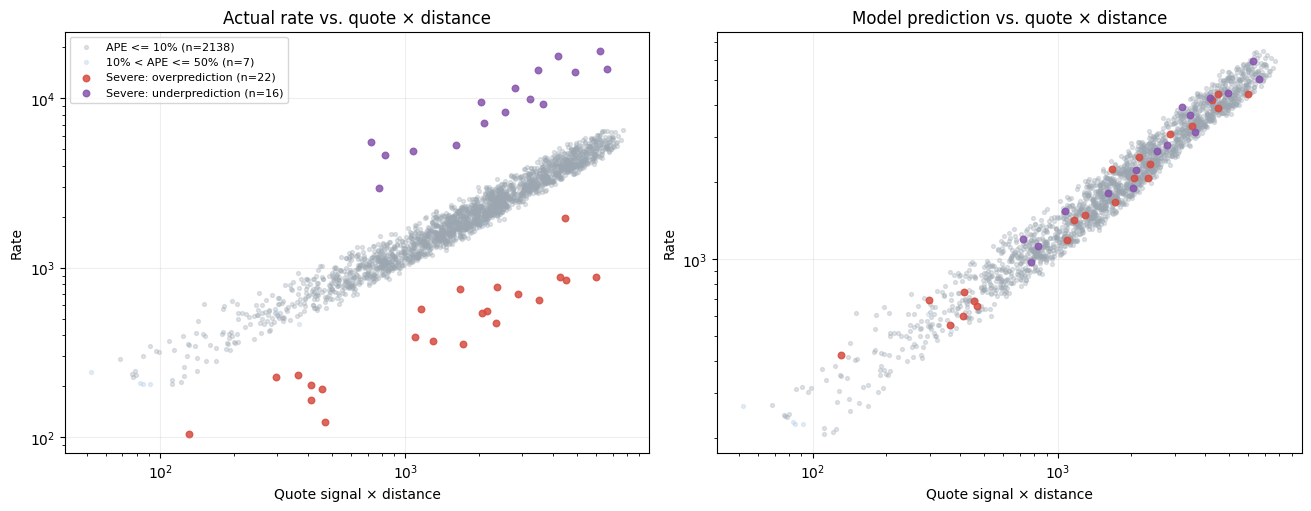

In [12]:
outlier_comparison, outlier_summary, outlier_medians, outlier_categories, worst_peers = compare_test_outliers(
    residuals, development_raw, holdout_df, threshold=50,
)
display(outlier_summary.round(3))
display(outlier_medians.round(3))
display(outlier_categories.round(2))
display(worst_peers.round(3))
comparison_figure = plot_outlier_comparison(outlier_comparison, threshold=50)
comparison_figure.savefig(DATA_DIR.parent / 'outputs' / 'test-outlier-comparison.png', dpi=150, facecolor='white')
plt.show()
plt.close(comparison_figure)


The largest differences are in the realized target, rather than route novelty: severe-error lanes are present in development, and quote, weight and route ratios overlap the ordinary-error population. The five worst targets are far below rates of approximately matched historical loads; another severe group has unusually high targets. This is consistent with an unobserved pricing factor or target anomalies, but does not prove either explanation. City/equipment counts are descriptive and small; they do not establish a stable predictive rule. Removing cases using their test errors would bias evaluation.

## 6. Save final model

Save the full-train submission model, fitted preprocessing, city/route references, feature order and metadata. The target transform is `log` for fitting and `exp` for predictions. Reload verification checks that the saved native model produces identical predictions.

In [13]:
interval_calibration = calibrate_rate_interval(test_actual, test_predicted, coverage=.90)
interval_calibration.update(calibration_start=str(holdout_raw.date.min().date()),
                            calibration_end=str(holdout_raw.date.max().date()))
model_directory = save_model_bundle(
    final_model, DATA_DIR.parent / 'outputs' / 'final-model',
    feature_state=final_feature_state, feature_columns=feature_columns, cat_features=cat_features,
    city_centers=city_centers, route_table=route_table,
    metadata=dict(target='posted_rate', target_transform='log', prediction_transform='exp',
                  training_start=str(raw['train'].date.min().date()),
                  training_end=str(raw['train'].date.max().date()),
                  training_rows=len(full_train_df), iterations=final_iterations,
                  study_name=study.study_name, best_trial=study.best_trial.number,
                  weighted_cv_mape_pct=weighted_mape, test_metrics=test_metrics.iloc[0].to_dict(),
                  interval_calibration=interval_calibration,
                  golden_features=golden_features, golden_borders=optimizer.golden_borders_,
                  here_snapshot=HERE_SNAPSHOT,
                  market_fit_scope='Known train + validation market_index inputs; no rate targets'),
    verification_features=val_df[feature_columns].head(100),
)
print(f'Saved model and preprocessing: {model_directory.resolve()}')


Saved model and preprocessing: /Users/asgatakmaev/Desktop/business/spotter_freight_rate_assessment/outputs/final-model
